# Spam Classification
Cleaning → EDA → Training → Tuning → Evaluation

Keep `mail_data.csv` in the notebook working folder. Run the cells in order.

## 1. Import Libraries

In [56]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## 2. Load Data

In [57]:
from IPython.display import display

In [58]:
df = pd.read_csv('mail_data.csv')
df.head()

,Category,Message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


In [59]:
print('Shape:', df.shape)
df.info()

Shape: (5572, 2)
<class 'pandas.DataFrame'>
RangeIndex: 5572 entries, 0 to 5571
Data columns (total 2 columns):
 #   Column    Non-Null Count  Dtype
---  ------    --------------  -----
 0   Category  5572 non-null   str  
 1   Message   5572 non-null   str  
dtypes: str(2)
memory usage: 542.2 KB


In [60]:
display(df.isna().sum())
print('Duplicates:', df.duplicated().sum())
display(df['Category'].value_counts())

Category    0
Message     0
dtype: int64

Duplicates: 415


Category
ham     4825
spam     747
Name: count, dtype: int64

## 3. Cleaning
Remove empty messages and duplicates before splitting the data.

In [61]:
df = df[['Category', 'Message']].dropna().copy()
df['Category'] = df['Category'].str.strip().str.lower()
df['Message'] = df['Message'].astype(str)
df['clean_message'] = df['Message'].str.lower().str.replace(r'\s+', ' ', regex=True).str.strip()
df = df[df['clean_message'] != ''].copy()

In [62]:
assert set(df['Category']) <= {'ham', 'spam'}
label_counts = df.groupby('clean_message')['Category'].nunique()
conflicts = label_counts[label_counts > 1].index
df = df[~df['clean_message'].isin(conflicts)]
df = df.drop_duplicates('clean_message').reset_index(drop=True)
print('After cleaning:', df.shape)

After cleaning: (5156, 3)


In [63]:
df['target'] = df['Category'].map({'ham': 0, 'spam': 1})
display(df.head())

,Category,Message,clean_message,target
0,ham,"Go until jurong point, crazy.. Available only ...","go until jurong point, crazy.. available only ...",0
1,ham,Ok lar... Joking wif u oni...,ok lar... joking wif u oni...,0
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,free entry in 2 a wkly comp to win fa cup fina...,1
3,ham,U dun say so early hor... U c already then say...,u dun say so early hor... u c already then say...,0
4,ham,"Nah I don't think he goes to usf, he lives aro...","nah i don't think he goes to usf, he lives aro...",0


## 4. Train / Test Split
80% training, 20% testing. Spam = 1, Ham = 0.

In [64]:
from sklearn.model_selection import train_test_split

SEED = 42

In [65]:
train_df, test_df = train_test_split(
    df, test_size=0.2, stratify=df['target'], random_state=SEED
)
train_df, test_df = train_df.copy(), test_df.copy()

In [66]:
X_train, y_train = train_df['Message'], train_df['target']
X_test, y_test = test_df['Message'], test_df['target']
assert set(train_df['clean_message']).isdisjoint(test_df['clean_message'])
print('Train:', len(X_train))
print('Test:', len(X_test))

Train: 4124
Test: 1032


## 5. EDA
Explore training data only. Accuracy alone can hide poor spam detection.

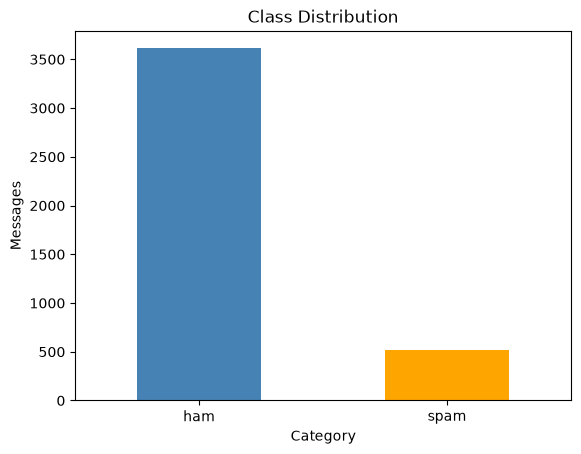

In [67]:
train_df['Category'].value_counts().plot.bar(color=['steelblue', 'orange'], rot=0)
plt.title('Class Distribution')
plt.ylabel('Messages')
plt.show()

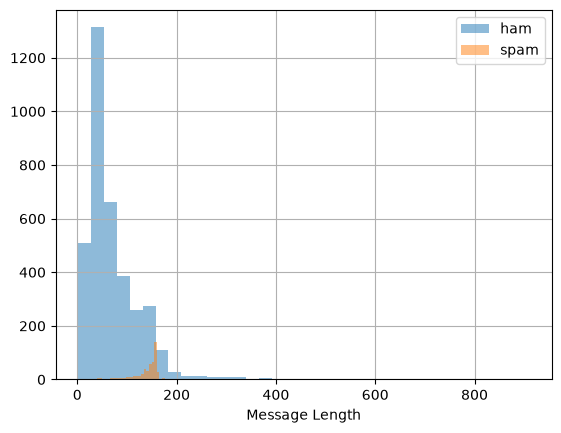

In [68]:
train_df['length'] = train_df['Message'].str.len()
for label in ['ham', 'spam']:
    train_df.loc[train_df['Category'] == label, 'length'].hist(bins=35, alpha=0.5, label=label)
plt.xlabel('Message Length')
plt.legend()
plt.show()

In [69]:
display(train_df.groupby('Category')['length'].describe().round(1))

,count,mean,std,min,25%,50%,75%,max
Category,,,,,,,,
ham,3611.0,71.1,56.4,2.0,34.0,53.0,92.0,910.0
spam,513.0,137.3,30.0,13.0,132.0,148.0,156.0,197.0


## 6. TF-IDF & Models
A pipeline fits TF-IDF inside each training fold to prevent leakage.

In [70]:
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer

In [71]:
def make_pipeline(classifier):
    return Pipeline([('tfidf', TfidfVectorizer(lowercase=True, strip_accents='unicode')),
                     ('model', classifier)])

In [72]:
from sklearn.dummy import DummyClassifier
from sklearn.naive_bayes import MultinomialNB, ComplementNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC

In [73]:
models = {
    'Majority baseline': make_pipeline(DummyClassifier(strategy='most_frequent')),
    'Multinomial NB': make_pipeline(MultinomialNB()),
    'Complement NB': make_pipeline(ComplementNB()),
    'Logistic Regression': make_pipeline(LogisticRegression(max_iter=2000, random_state=SEED)),
    'Linear SVM': make_pipeline(LinearSVC(random_state=SEED, max_iter=10000)),
}

## 7. Model Comparison
Compare 5-fold CV scores. Choose the model with the highest spam F1.

In [74]:
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import precision_score, make_scorer

In [75]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
scoring = {
    'accuracy': 'accuracy',
    'precision': make_scorer(precision_score, zero_division=0),
    'recall': 'recall',
    'f1': 'f1'
}

In [76]:
from sklearn.model_selection import cross_validate

In [77]:
rows = []
for name, pipeline in models.items():
    scores = cross_validate(pipeline, X_train, y_train, cv=cv, scoring=scoring)
    row = {'model': name}
    for metric in scoring:
        row[metric] = scores['test_' + metric].mean()
    rows.append(row)

In [78]:
comparison = pd.DataFrame(rows).set_index('model').sort_values('f1', ascending=False)
display(comparison.round(4))

,accuracy,precision,recall,f1
model,,,,
Linear SVM,0.9862,0.9810,0.9064,0.9422
Complement NB,0.9748,0.9321,0.8596,0.8942
Logistic Regression,0.9617,0.9894,0.6998,0.8190
Multinomial NB,0.9471,1.0000,0.5751,0.7295
Majority baseline,0.8756,0.0000,0.0000,0.0000


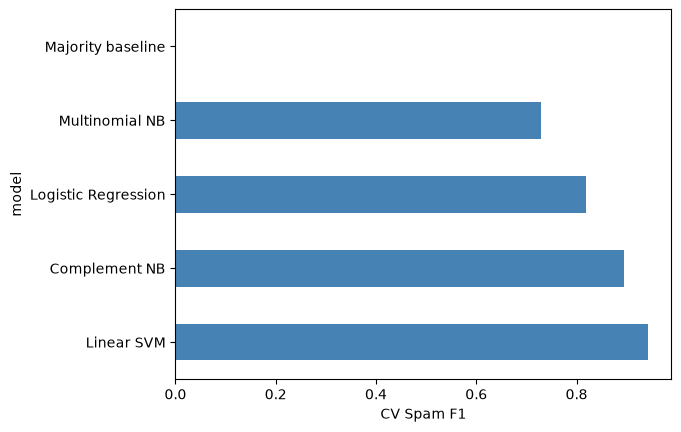

Best model: Linear SVM


In [79]:
comparison['f1'].plot.barh(color='steelblue')
plt.xlabel('CV Spam F1')
plt.show()
winner_name = comparison.drop(index='Majority baseline')['f1'].idxmax()
print('Best model:', winner_name)

## 8. Hyperparameter Tuning
Tune the best model using training data only.

In [80]:
param_grid = {
    'tfidf__ngram_range': [(1,1), (1,2)],
    'tfidf__min_df': [1,2],
    'tfidf__sublinear_tf': [False,True],
}

In [81]:
if winner_name in ['Multinomial NB','Complement NB']:
    param_grid['model__alpha'] = [0.1, 0.5, 1.0]
else:
    param_grid['model__C'] = [0.5, 1.0, 3.0]
    param_grid['model__class_weight'] = [None, 'balanced']

In [82]:
from sklearn.model_selection import GridSearchCV

In [83]:
search = GridSearchCV(models[winner_name], param_grid, scoring=scoring, refit='f1',
                      cv=cv, n_jobs=1, return_train_score=True, error_score='raise')

In [84]:
search.fit(X_train, y_train)
best_model = search.best_estimator_

In [85]:
print('Configurations evaluated:', len(search.cv_results_['params']))
print('Best parameters:', search.best_params_)
print(f'Untuned CV F1: {comparison.loc[winner_name, "f1"]:.4f}')
print(f'Tuned CV F1:   {search.best_score_:.4f}')

Configurations evaluated: 48
Best parameters: {'model__C': 0.5, 'model__class_weight': 'balanced', 'tfidf__min_df': 2, 'tfidf__ngram_range': (1, 2), 'tfidf__sublinear_tf': True}
Untuned CV F1: 0.9422
Tuned CV F1:   0.9525


In [86]:
tuning_results = pd.DataFrame(search.cv_results_).sort_values('rank_test_f1')
display(tuning_results[['rank_test_f1','mean_train_f1','mean_test_f1','std_test_f1','params']].head(10))

,rank_test_f1,mean_train_f1,mean_test_f1,std_test_f1,params
15,1,0.997081,0.952550,0.016427,"{'model__C': 0.5, 'model__class_weight': 'bala..."
43,2,1.000000,0.952472,0.016450,"{'model__C': 3.0, 'model__class_weight': 'bala..."
34,3,1.000000,0.952296,0.017848,"{'model__C': 3.0, 'model__class_weight': None,..."
35,4,1.000000,0.950286,0.018020,"{'model__C': 3.0, 'model__class_weight': None,..."
14,5,0.995871,0.949736,0.017805,"{'model__C': 0.5, 'model__class_weight': 'bala..."
33,6,1.000000,0.949697,0.008406,"{'model__C': 3.0, 'model__class_weight': None,..."
42,7,1.000000,0.949571,0.015113,"{'model__C': 3.0, 'model__class_weight': 'bala..."
37,8,0.999024,0.949533,0.013006,"{'model__C': 3.0, 'model__class_weight': None,..."
45,9,0.998052,0.949111,0.010358,"{'model__C': 3.0, 'model__class_weight': 'bala..."
38,10,0.999024,0.948546,0.016935,"{'model__C': 3.0, 'model__class_weight': None,..."


## 9. Test Evaluation
Precision: correct spam flags. Recall: spam caught. F1 balances both.

In [87]:
pred = best_model.predict(X_test)
score = (best_model.decision_function(X_test) if hasattr(best_model, 'decision_function')
         else best_model.predict_proba(X_test)[:,1])

In [88]:
from sklearn.metrics import (
    accuracy_score, recall_score, f1_score, classification_report,
    roc_auc_score, average_precision_score
)

In [89]:
test_metrics = {
    'accuracy':accuracy_score(y_test,pred),
    'spam_precision':precision_score(y_test,pred,zero_division=0),
    'spam_recall':recall_score(y_test,pred,zero_division=0),
    'spam_f1':f1_score(y_test,pred,zero_division=0),
    'roc_auc':roc_auc_score(y_test,score),
    'average_precision':average_precision_score(y_test,score),
}
display(pd.Series(test_metrics,name='held_out_test').to_frame().round(4))
print(classification_report(y_test,pred,labels=[0,1],target_names=['ham','spam'],zero_division=0))

,held_out_test
accuracy,0.9777
spam_precision,0.9487
spam_recall,0.8672
spam_f1,0.9061
roc_auc,0.9887
average_precision,0.9601


              precision    recall  f1-score   support

         ham       0.98      0.99      0.99       904
        spam       0.95      0.87      0.91       128

    accuracy                           0.98      1032
   macro avg       0.97      0.93      0.95      1032
weighted avg       0.98      0.98      0.98      1032



## 10. Confusion Matrix

In [90]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

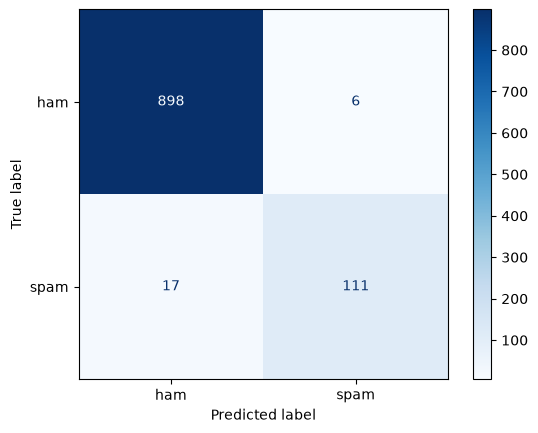

False positives: 6
False negatives: 17


In [91]:
ConfusionMatrixDisplay.from_predictions(y_test, pred, display_labels=['ham', 'spam'], cmap='Blues')
plt.show()
tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
print('False positives:', fp)
print('False negatives:', fn)

## 11. ROC & Precision–Recall
SVM decision scores are not probabilities.

In [92]:
from sklearn.metrics import RocCurveDisplay, PrecisionRecallDisplay

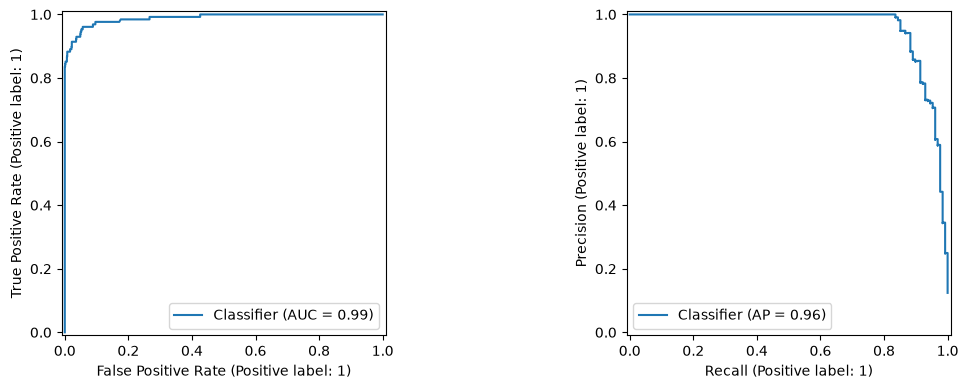

In [93]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
RocCurveDisplay.from_predictions(y_test, score, ax=axes[0])
PrecisionRecallDisplay.from_predictions(y_test, score, ax=axes[1])
plt.tight_layout()
plt.show()

## 12. Error Analysis
Inspect mistakes without retuning on the test set.

In [94]:
errors = test_df[['Message','Category']].copy()
errors['prediction'] = np.where(pred == 1,'spam','ham')
errors['score'] = score
errors = errors[errors['Category'] != errors['prediction']]

In [95]:
display(errors.head(10))

,Message,Category,prediction,score
3766,You will be receiving this week's Triple Echo ...,spam,ham,-0.275227
1229,Can U get 2 phone NOW? I wanna chat 2 set up m...,spam,ham,-0.046456
3331,I'm at home. Please call,ham,spam,0.060413
3630,Oh my god! I've found your number again! I'm s...,spam,ham,-0.617210
3943,Missed call alert. These numbers called but le...,spam,ham,-0.185683
1028,I'm at work. Please call,ham,spam,0.156568
3817,TBS/PERSOLVO. been chasing us since Sept for£3...,spam,ham,-0.365061
1810,Would you like to see my XXX pics they are so ...,spam,ham,-0.226981
2541,Hello darling how are you today? I would love ...,spam,ham,-0.835917
4613,I'm vivek:)i got call from your number.,ham,spam,0.282140


## 13. Try New Messages

In [96]:
def predict_messages(messages):
    if isinstance(messages, str):
        messages = [messages]
    if not messages or any(not isinstance(m,str) or not m.strip() for m in messages):
        raise ValueError('Provide one or more non-empty text messages.')
    labels = best_model.predict(messages)
    return pd.DataFrame({'Message':messages, 'Prediction':np.where(labels == 1,'spam','ham')})

In [97]:
display(predict_messages([
    'Congratulations! You won a free prize. Call now!',
    'Hi, are we meeting at the library at 5 pm?'
]))

,Message,Prediction
0,Congratulations! You won a free prize. Call now!,spam
1,"Hi, are we meeting at the library at 5 pm?",ham


## 14. Save Model
Save TF-IDF and the classifier together.

In [98]:
import joblib

In [99]:
joblib.dump(best_model, 'spam_classifier.joblib')
loaded_model = joblib.load('spam_classifier.joblib')
assert np.array_equal(loaded_model.predict(X_test), pred)
print('Model saved and reloaded successfully.')

Model saved and reloaded successfully.


## 15. Results
These results apply to this dataset and split; new message styles may perform differently.

In [100]:
print('Selected model:', winner_name)
print(f"Accuracy: {test_metrics['accuracy']:.2%}")
print(f"Spam Precision: {test_metrics['spam_precision']:.2%}")
print(f"Spam Recall: {test_metrics['spam_recall']:.2%}")
print(f"Spam F1: {test_metrics['spam_f1']:.2%}")

Selected model: Linear SVM
Accuracy: 97.77%
Spam Precision: 94.87%
Spam Recall: 86.72%
Spam F1: 90.61%
